In [1]:
# ============================================================
# HOUSE OCCUPANCY PREDICTION
# This project predicts whether a room is occupied using sensor data.
# ============================================================

In [2]:
# STEP 1: IMPORT LIBRARIES
# Import pandas to work with the dataset.
# Import matplotlib to create graphs.

import pandas as pd
import matplotlib.pyplot as plt

# Import functions to split data, scale values, and create pipelines.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Import four classification algorithms.
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Import metrics to evaluate model accuracy and predictions.
from sklearn.metrics import accuracy_score, confusion_matrix

In [3]:
# STEP 2: LOAD DATASET
# Read the occupancy dataset from the given file path.

data = pd.read_csv(r"C:\ML\occupancy.txt")

# Display the number of rows and columns.
print("\nDataset Shape:", data.shape)

# Display the first five records.
print("\nFirst 5 Records:")
print(data.head())

# Display all column names.
print("\nColumn Names:")
print(data.columns)

# Display column names, data types, and non-null counts.
print("\nDataset Information:")
data.info()

# Display statistical information about numerical columns.
print("\nStatistical Information:")
print(data.describe())


Dataset Shape: (9752, 7)

First 5 Records:
                  date  Temperature   Humidity       Light          CO2  \
1  2015-02-11 14:48:00      21.7600  31.133333  437.333333  1029.666667   
2  2015-02-11 14:49:00      21.7900  31.000000  437.333333  1000.000000   
3  2015-02-11 14:50:00      21.7675  31.122500  434.000000  1003.750000   
4  2015-02-11 14:51:00      21.7675  31.122500  439.000000  1009.500000   
5  2015-02-11 14:51:59      21.7900  31.133333  437.333333  1005.666667   

   HumidityRatio  Occupancy  
1       0.005021          1  
2       0.005009          1  
3       0.005022          1  
4       0.005022          1  
5       0.005030          1  

Column Names:
Index(['date', 'Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio',
       'Occupancy'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 9752 entries, 1 to 9752
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------

In [4]:
# STEP 3: CHECK MISSING VALUES
# Check the number of missing values in each column.

print("\nMissing Values:")
print(data.isnull().sum())


Missing Values:
date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64


In [5]:
# STEP 4: CHECK TARGET VALUES
# Count how many records belong to each occupancy class.

print("\nOccupancy Distribution:")
print(data["Occupancy"].value_counts())

# Explain the meaning of the target values.
print("\n0 = Not Occupied")
print("1 = Occupied")


Occupancy Distribution:
Occupancy
0    7703
1    2049
Name: count, dtype: int64

0 = Not Occupied
1 = Occupied


In [6]:
# STEP 5: SELECT INPUT AND OUTPUT
# X contains the five sensor readings used for prediction.

X = data[
    [
        "Temperature",
        "Humidity",
        "Light",
        "CO2",
        "HumidityRatio"
    ]
]

# y contains the actual occupancy labels.
y = data["Occupancy"]

# Display the selected input columns and their count.
print("\nInput Parameters:", X.columns.tolist())
print("Number of Input Parameters:", X.shape[1])
print("Output Parameter: Occupancy")


Input Parameters: ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']
Number of Input Parameters: 5
Output Parameter: Occupancy


In [7]:
# STEP 6: SPLIT DATA INTO TRAINING AND TESTING
# Use 80% of the data for training and 20% for testing.
# random_state=42 makes the split reproducible.
# stratify=y maintains the target-class proportions.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of training and testing records.
print("\nTraining Records:", len(X_train))
print("Testing Records:", len(X_test))


Training Records: 7801
Testing Records: 1951


In [8]:
# STEP 7: CREATE MACHINE LEARNING MODELS
# Store the four classification models in a dictionary.
# StandardScaler scales input features for Logistic Regression and SVM.
# Random Forest uses 100 decision trees.

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ])
}

In [9]:
# STEP 8: TRAIN MODELS AND CALCULATE ACCURACY
# Store the accuracy of each model in the results dictionary.

results = {}

print("\nModel Accuracy:")

# Train each model and predict the test data.
for name, model in models.items():

    model.fit(X_train, y_train)

    prediction = model.predict(X_test)

    # Calculate accuracy as a percentage.
    accuracy = accuracy_score(y_test, prediction) * 100

    # Save and display the model's accuracy.
    results[name] = accuracy

    print(name, ":", round(accuracy, 2), "%")


Model Accuracy:
Logistic Regression : 99.33 %
Decision Tree : 99.23 %
Random Forest : 99.54 %
SVM : 99.33 %


In [10]:
# STEP 9: FIND BEST MODEL
# Select the model with the highest accuracy.

best_model = max(results, key=results.get)
best_accuracy = results[best_model]

# Display the best model and its accuracy.
print("\nBest Model:", best_model)
print("Best Accuracy:", round(best_accuracy, 2), "%")


Best Model: Random Forest
Best Accuracy: 99.54 %


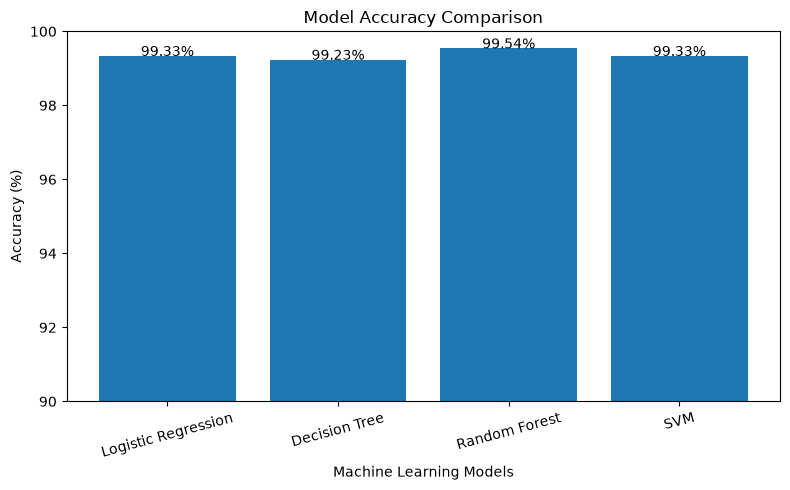

In [11]:
# STEP 10: MODEL ACCURACY COMPARISON
# Create a bar graph to compare the accuracy of all models.

plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

# Display each accuracy value above its bar.
for i, value in enumerate(results.values()):
    plt.text(i, value, f"{value:.2f}%", ha="center")

# Add graph labels and title.
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=15)
plt.ylim(90, 100)
plt.tight_layout()
plt.show()

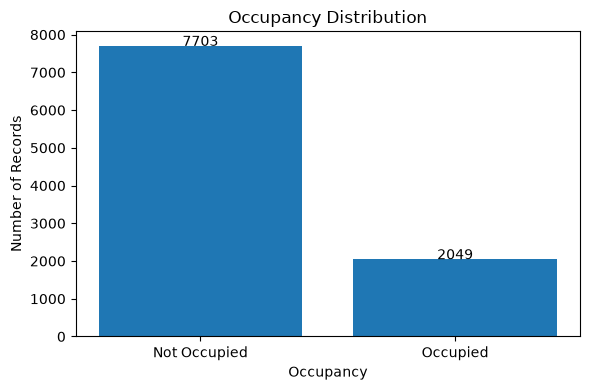

In [12]:
# STEP 11: OCCUPANCY DISTRIBUTION
# Count the records for each occupancy class.

counts = data["Occupancy"].value_counts().sort_index()

# Create a bar graph showing occupied and unoccupied records.
plt.figure(figsize=(6, 4))

plt.bar(
    ["Not Occupied", "Occupied"],
    counts.values
)

# Display the count above each bar.
for i, value in enumerate(counts.values):
    plt.text(i, value, str(value), ha="center")

# Add graph labels and title.
plt.xlabel("Occupancy")
plt.ylabel("Number of Records")
plt.title("Occupancy Distribution")
plt.tight_layout()
plt.show()


Confusion Matrix:
[[1536    5]
 [   4  406]]


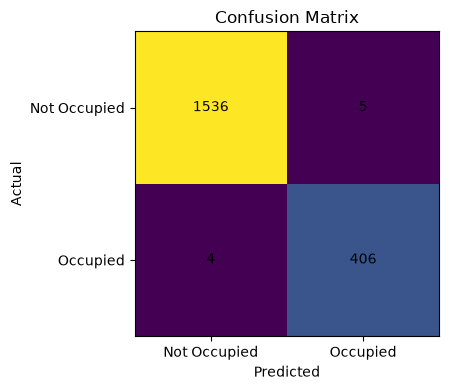

In [13]:
# STEP 12: CONFUSION MATRIX
# Select the best-performing model.
# Predict occupancy for the test data.

best = models[best_model]

prediction = best.predict(X_test)

# Compare actual and predicted labels.
cm = confusion_matrix(y_test, prediction)

print("\nConfusion Matrix:")
print(cm)

# Display the confusion matrix as a graph.
plt.figure(figsize=(5, 4))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# Label the horizontal and vertical axes.
plt.xticks(
    [0, 1],
    ["Not Occupied", "Occupied"]
)

plt.yticks(
    [0, 1],
    ["Not Occupied", "Occupied"]
)

# Display each confusion matrix value inside its box.
for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [14]:
# STEP 13: FINAL RESULT
# Display the dataset details, model accuracies, and best model.

print("\n======================================")
print("        FINAL PROJECT RESULT")
print("======================================")

print("Dataset Shape:", data.shape)
print("Input Parameters:", X.shape[1])
print("Output Parameter: Occupancy")

# Display the accuracy of every model.
print("\nModel Accuracies:")

for model, accuracy in results.items():
    print(model, "->", round(accuracy, 2), "%")

# Display the best model and its accuracy.
print("\nBest Model:", best_model)
print("Best Accuracy:", round(best_accuracy, 2), "%")

print("======================================")


        FINAL PROJECT RESULT
Dataset Shape: (9752, 7)
Input Parameters: 5
Output Parameter: Occupancy

Model Accuracies:
Logistic Regression -> 99.33 %
Decision Tree -> 99.23 %
Random Forest -> 99.54 %
SVM -> 99.33 %

Best Model: Random Forest
Best Accuracy: 99.54 %


In [15]:
# STEP 14: NEW SAMPLE PREDICTION USING ALL MODELS
# Create a sample with five sensor readings.
# Each trained model predicts whether this sample is occupied.

sample = pd.DataFrame([{
    "Temperature": 25.0,
    "Humidity": 27.0,
    "Light": 550.0,
    "CO2": 600.0,
    "HumidityRatio": 0.004
}])

# Display the sample input values.
print("\nNew Sample Input:")
print(sample)

# Display predictions from all four models.
print("\nPredictions from All Models:")

for name, model in models.items():

    prediction = model.predict(sample)[0]

    print("\nModel:", name)
    print("Predicted Class:", prediction)

    # Convert the predicted class into a readable label.
    if prediction == 1:
        print("Model Output: Occupied")
    else:
        print("Model Output: Not Occupied")


New Sample Input:
   Temperature  Humidity  Light    CO2  HumidityRatio
0         25.0      27.0  550.0  600.0          0.004

Predictions from All Models:

Model: Logistic Regression
Predicted Class: 1
Model Output: Occupied

Model: Decision Tree
Predicted Class: 1
Model Output: Occupied

Model: Random Forest
Predicted Class: 1
Model Output: Occupied

Model: SVM
Predicted Class: 1
Model Output: Occupied
